# 10 — Localization ensemble (combine trained U-Net runs)

Loads every trained localization run (`saved_models/localization/*_best.pth`, e.g. the first run and the clean-label run),
averages their probability maps with **weights + threshold chosen on validation**, and reports localization **and**
quantification on **test** — next to each single run, so you can see if the ensemble really helps.

Evaluated on the **verified-mask** val/test images (same filtering as notebook 07 v2). Needs a GPU (your RTX 4050); takes a few minutes.

In [1]:
# ============================================================
# 1. Setup
# ============================================================
import os, sys, json, itertools, subprocess, time
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
def ensure(module, pip_name=None):
    try: __import__(module)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
ensure("segmentation_models_pytorch", "segmentation-models-pytorch")
import numpy as np, pandas as pd, torch, torch.nn.functional as F, matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from PIL import Image
from tqdm.auto import tqdm
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupKFold
from scipy.stats import pearsonr, spearmanr
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
Image.MAX_IMAGE_PIXELS = None

PROJECT_DIR = (Path("/content/drive/MyDrive/AI_Image_Project") if IN_COLAB
               else Path(os.environ.get("AI_PROJECT_DIR", r"C:\AI_Image_Project")))   # <- laptop folder
BASE_DIR = PROJECT_DIR / "Partial_AI_5000"
LOC_FEATURES_DIR = PROJECT_DIR / "features" / "localization"
LOC_MODELS_DIR = PROJECT_DIR / "saved_models" / "localization"
OUT_DIR = PROJECT_DIR / "results" / "localization" / "ensemble"; OUT_DIR.mkdir(parents=True, exist_ok=True)

RUNS = None          # None = every *_best.pth found; or e.g. ["Unet_resnet34_crop512", "Unet_resnet34_crop512_plusbbox_clean"]
CLEAN_LABELS = True  # evaluate on verified-mask images only (needs features/localization/mask_audit.csv)
TTA = True
WEIGHT_STEP = 0.1    # weight grid step (0.1 for 2 models; use 0.25 for 3+ to keep it fast)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
# ============================================================
# 2. Evaluation images: verified segm val/test (same split as 06/07)
# ============================================================
pairs = pd.read_csv(BASE_DIR / "pairs.csv"); pairs["pairs_row"] = np.arange(len(pairs))
segm_df = pairs[pairs["mask_type"] == "segm"].reset_index(drop=True)
source_ids = segm_df["source_id"].to_numpy()
val_idx, test_idx = np.load(LOC_FEATURES_DIR / "val_idx.npy"), np.load(LOC_FEATURES_DIR / "test_idx.npy")

if CLEAN_LABELS:
    AUDIT = pd.read_csv(LOC_FEATURES_DIR / "mask_audit.csv").set_index("row")
    a = AUDIT.loc[segm_df["pairs_row"].to_numpy()]
    use_csv = (a["verdict"] == "ok").to_numpy()
    use_alt = (~use_csv) & (a["alt_verdict"] == "ok").to_numpy() if "alt_verdict" in a else np.zeros(len(a), bool)
    if "alt_mask_path" in a:
        segm_df["mask_path"] = np.where(use_alt, a["alt_mask_path"].astype(str).to_numpy(), segm_df["mask_path"].to_numpy())
    keep = use_csv | use_alt
    val_idx, test_idx = val_idx[keep[val_idx]], test_idx[keep[test_idx]]
print(f"Validation images: {len(val_idx)} | Test images: {len(test_idx)}")

Validation images: 131 | Test images: 141


In [3]:
# ============================================================
# 3. Load the trained runs
# ============================================================
ckpt_files = sorted(LOC_MODELS_DIR.glob("*_best.pth"))
if RUNS is not None:
    ckpt_files = [LOC_MODELS_DIR / f"{r}_best.pth" for r in RUNS]
assert ckpt_files, f"No *_best.pth in {LOC_MODELS_DIR}"
models, names, max_sides = [], [], []
for f in ckpt_files:
    ck = torch.load(f, map_location=device, weights_only=False); cfg = ck["cfg"]
    m = smp.create_model(arch=cfg["ARCH"], encoder_name=cfg["ENCODER"], encoder_weights=None, in_channels=3, classes=1)
    m.load_state_dict(ck["model"]); m.to(device).to(memory_format=torch.channels_last).eval()
    models.append(m); names.append(f.name[: -len("_best.pth")]); max_sides.append(cfg["MAX_SIDE"])
    print(f"Loaded {names[-1]}  (epoch {ck.get('epoch')}, {cfg['ARCH']}-{cfg['ENCODER']})")
MAX_SIDE = max_sides[0]
M = len(models)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255
THRS = np.round(np.r_[0.01, 0.02, 0.03, 0.04, np.arange(0.05, 0.951, 0.05)], 2)
N_BINS = 1000

def load_pair(i):
    r = segm_df.iloc[int(i)]
    im = Image.open(BASE_DIR / r["manipulated_path"]).convert("RGB")
    s = min(1.0, MAX_SIDE / max(im.size)); size = (max(1, round(im.size[0] * s)), max(1, round(im.size[1] * s)))
    if im.size != size: im = im.resize(size, Image.Resampling.BICUBIC)
    mk = Image.open(BASE_DIR / r["mask_path"]).convert("L")
    if mk.size != size: mk = mk.resize(size, Image.Resampling.NEAREST)
    return np.asarray(im), np.asarray(mk) > 127

@torch.no_grad()
def predict_prob(model, img):
    H, W = img.shape[:2]
    x = ((torch.from_numpy(np.array(img)).to(device).permute(2, 0, 1)[None].float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)
    ph, pw = (-H) % 32, (-W) % 32
    if ph or pw: x = F.pad(x, (0, pw, 0, ph), mode="reflect")
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        p = torch.sigmoid(model(x).float())
        if TTA: p = 0.5 * (p + torch.sigmoid(model(x.flip(-1)).float()).flip(-1))
    return p[0, 0, :H, :W]

# Weight combinations on the simplex (includes every single model and the equal average)
steps = int(round(1 / WEIGHT_STEP))
COMBOS = [np.array(w) / steps for w in itertools.product(range(steps + 1), repeat=M) if sum(w) == steps]
if M > 1 and not any(np.allclose(c, 1 / M) for c in COMBOS): COMBOS.append(np.full(M, 1 / M))
print(f"{M} runs -> {len(COMBOS)} weight combinations x {len(THRS)} thresholds")

Loaded Unet_resnet34_crop512  (epoch 22, Unet-resnet34)
Loaded Unet_resnet34_crop512_plusbbox_clean  (epoch 24, Unet-resnet34)
2 runs -> 11 weight combinations x 23 thresholds


In [4]:
# ============================================================
# 4. One pass over val and test: statistics for every weight combination and threshold
# ============================================================
@torch.no_grad()
def run_pass(indices, desc):
    n, C, T = len(indices), len(COMBOS), len(THRS)
    st = dict(inter=np.zeros((n, C, T)), pred=np.zeros((n, C, T)), gt=np.zeros(n), npx=np.zeros(n), soft=np.zeros((n, C)),
              hpos=torch.zeros(C, N_BINS, device=device), hneg=torch.zeros(C, N_BINS, device=device))
    thr = torch.tensor(THRS, device=device, dtype=torch.float32).view(-1, 1, 1)
    torch.backends.cudnn.benchmark = False
    for k, i in enumerate(tqdm(indices, desc=desc)):
        img, gt = load_pair(i)
        probs = torch.stack([predict_prob(m, img) for m in models])          # (M, H, W)
        g = torch.from_numpy(gt).to(device)
        st["gt"][k], st["npx"][k] = g.sum().item(), g.numel()
        for c, w in enumerate(COMBOS):
            p = torch.tensordot(torch.tensor(w, device=device, dtype=torch.float32), probs, 1)
            pr = p.unsqueeze(0) >= thr
            st["inter"][k, c] = (pr & g).sum((1, 2)).cpu().numpy()
            st["pred"][k, c] = pr.sum((1, 2)).cpu().numpy()
            st["soft"][k, c] = p.sum().item()
            st["hpos"][c] += torch.histc(p[g], N_BINS, 0, 1); st["hneg"][c] += torch.histc(p[~g], N_BINS, 0, 1)
    st["hpos"], st["hneg"] = st["hpos"].cpu().numpy(), st["hneg"].cpu().numpy()
    return st

t0 = time.time()
S_val = run_pass(val_idx, "Validation")
S_test = run_pass(test_idx, "Test")
print(f"Done in {(time.time()-t0)/60:.1f} min")

Validation:   0%|          | 0/131 [00:00<?, ?it/s]

Test:   0%|          | 0/141 [00:00<?, ?it/s]

Done in 0.8 min


In [5]:
# ============================================================
# 5. LOCALIZATION: pick weights + threshold on validation, report on test
# ============================================================
def per_image_f1(S, c):
    return 2 * S["inter"][:, c] / (S["pred"][:, c] + S["gt"][:, None] + 1e-9)     # (n, T)

def loc_metrics(S, c, t):
    I, P, G = S["inter"][:, c, t], S["pred"][:, c, t], S["gt"]
    tp, fp = np.cumsum(S["hpos"][c][::-1]), np.cumsum(S["hneg"][c][::-1])
    tpr, fpr = np.r_[0, tp / max(tp[-1], 1)], np.r_[0, fp / max(fp[-1], 1)]
    trap = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
    return {"threshold": float(THRS[t]), "F1_per_image_mean": float((2 * I / (P + G + 1e-9)).mean()),
            "IoU_per_image_mean": float((I / (P + G - I + 1e-9)).mean()),
            "F1_global": float(2 * I.sum() / (P.sum() + G.sum() + 1e-9)),
            "Precision_global": float(I.sum() / (P.sum() + 1e-9)), "Recall_global": float(I.sum() / (G.sum() + 1e-9)),
            "Pixel_AUC": float(trap(tpr, fpr)), "Pixel_AP": float(np.sum(np.diff(tpr) * tp / np.maximum(tp + fp, 1)))}

best_t = {c: int(np.argmax(per_image_f1(S_val, c).mean(0))) for c in range(len(COMBOS))}
val_score = {c: per_image_f1(S_val, c).mean(0)[best_t[c]] for c in range(len(COMBOS))}
BEST_C = max(val_score, key=val_score.get)

def label(c):
    w = COMBOS[c]
    if np.isclose(w.max(), 1): return f"Single: {names[int(w.argmax())]}"
    if np.allclose(w, w[0]):  return "Ensemble: equal average"
    return "Ensemble: weighted (" + ", ".join(f"{n}={x:.1f}" for n, x in zip(names, w) if x > 0) + ")"

show = sorted({c for c in range(len(COMBOS)) if np.isclose(COMBOS[c].max(), 1) or np.allclose(COMBOS[c], COMBOS[c][0])} | {BEST_C})
rows = []
for c in show:
    rows.append({"Model": label(c), "Split": "Validation", **loc_metrics(S_val, c, best_t[c])})
    rows.append({"Model": label(c), "Split": "Test", **loc_metrics(S_test, c, best_t[c])})
loc_table = pd.DataFrame(rows)
print("Chosen on validation:", label(BEST_C), f"@ threshold {THRS[best_t[BEST_C]]}\n")
lt = loc_table[loc_table.Split == "Test"].set_index("Model").drop(columns="Split")
lt["chosen_on_val"] = ["<- BEST" if m == label(BEST_C) else "" for m in lt.index]
print("TEST localization:")
display(lt.round(4)) if "display" in globals() else print(lt.round(4))

Chosen on validation: Ensemble: weighted (Unet_resnet34_crop512=0.3, Unet_resnet34_crop512_plusbbox_clean=0.7) @ threshold 0.25

TEST localization:
                                                    threshold  F1_per_image_mean  IoU_per_image_mean  F1_global  Precision_global  Recall_global  Pixel_AUC  Pixel_AP chosen_on_val
Model                                                                                                                                                                              
Single: Unet_resnet34_crop512_plusbbox_clean             0.25             0.5466              0.4673     0.7293            0.6533         0.8254     0.9668    0.8200              
Ensemble: weighted (Unet_resnet34_crop512=0.3, ...       0.25             0.5361              0.4551     0.7201            0.6381         0.8262     0.9752    0.8095       <- BEST
Ensemble: equal average                                  0.20             0.4868              0.3928     0.6717            0.5572   

In [6]:
# ============================================================
# 6. QUANTIFICATION (AI-edited area %) for the chosen combination
# ============================================================
def areas(S, c):
    return dict(gt=100 * S["gt"] / S["npx"], hard=100 * S["pred"][:, c] / S["npx"][:, None], soft=100 * S["soft"][:, c] / S["npx"])
c, t = BEST_C, best_t[BEST_C]
Av, At = areas(S_val, c), areas(S_test, c)
t_mae = int(np.argmin(np.abs(Av["hard"] - Av["gt"][:, None]).mean(0)))

def iso_fit_predict(x, y, xt): return IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=100).fit(x, y).predict(xt)
def iso_cv(x, y, g):
    n = min(5, len(np.unique(g)))
    if n < 2: return iso_fit_predict(x, y, x)
    out = np.zeros_like(y)
    for tr, te in GroupKFold(n).split(x, y, g): out[te] = iso_fit_predict(x[tr], y[tr], x[te])
    return out
gv = source_ids[val_idx]
EST = {f"Hard mask @F1-thr {THRS[t]:.2f}": (Av["hard"][:, t], At["hard"][:, t]),
       f"Hard mask @MAE-thr {THRS[t_mae]:.2f}": (Av["hard"][:, t_mae], At["hard"][:, t_mae]),
       "Soft (mean probability)": (Av["soft"], At["soft"]),
       "Soft + isotonic calibration": (iso_cv(Av["soft"], Av["gt"], gv), iso_fit_predict(Av["soft"], Av["gt"], At["soft"]))}

def qm(p, g):
    e = p - g
    return {"MAE_pp": np.abs(e).mean(), "MedianAE_pp": np.median(np.abs(e)), "RMSE_pp": np.sqrt((e**2).mean()),
            "Within_1pp_%": 100 * (np.abs(e) <= 1).mean(), "Within_2pp_%": 100 * (np.abs(e) <= 2).mean(),
            "Pearson_r": pearsonr(p, g)[0] if p.std() > 0 else np.nan, "Spearman_rho": spearmanr(p, g)[0] if p.std() > 0 else np.nan}
q_rows = []
for n, (pv, pt) in EST.items():
    q_rows += [{"Estimator": n, "Split": "Validation", **qm(pv, Av["gt"])}, {"Estimator": n, "Split": "Test", **qm(pt, At["gt"])}]
quant_table = pd.DataFrame(q_rows)
BEST_EST = quant_table[quant_table.Split == "Validation"].sort_values("MAE_pp").iloc[0]["Estimator"]
print("Area estimator chosen on validation:", BEST_EST)
print(f"Baseline (predict the validation median area for every image): test MAE = {np.abs(np.median(Av['gt']) - At['gt']).mean():.3f} pp")
qt = quant_table.set_index(["Estimator", "Split"]).round(3)
display(qt) if "display" in globals() else print(qt)

Area estimator chosen on validation: Hard mask @MAE-thr 0.60
Baseline (predict the validation median area for every image): test MAE = 2.709 pp
                                        MAE_pp  MedianAE_pp  RMSE_pp  Within_1pp_%  Within_2pp_%  Pearson_r  Spearman_rho
Estimator                   Split                                                                                        
Hard mask @F1-thr 0.25      Validation   1.724        0.705    2.947        61.832        75.573      0.887         0.785
                            Test         1.792        0.830    3.142        56.028        71.631      0.827         0.799
Hard mask @MAE-thr 0.60     Validation   1.087        0.660    1.665        65.649        81.679      0.949         0.836
                            Test         1.455        0.769    2.337        57.447        75.887      0.859         0.737
Soft (mean probability)     Validation   1.284        0.839    1.847        56.489        80.916      0.916         0.789
  

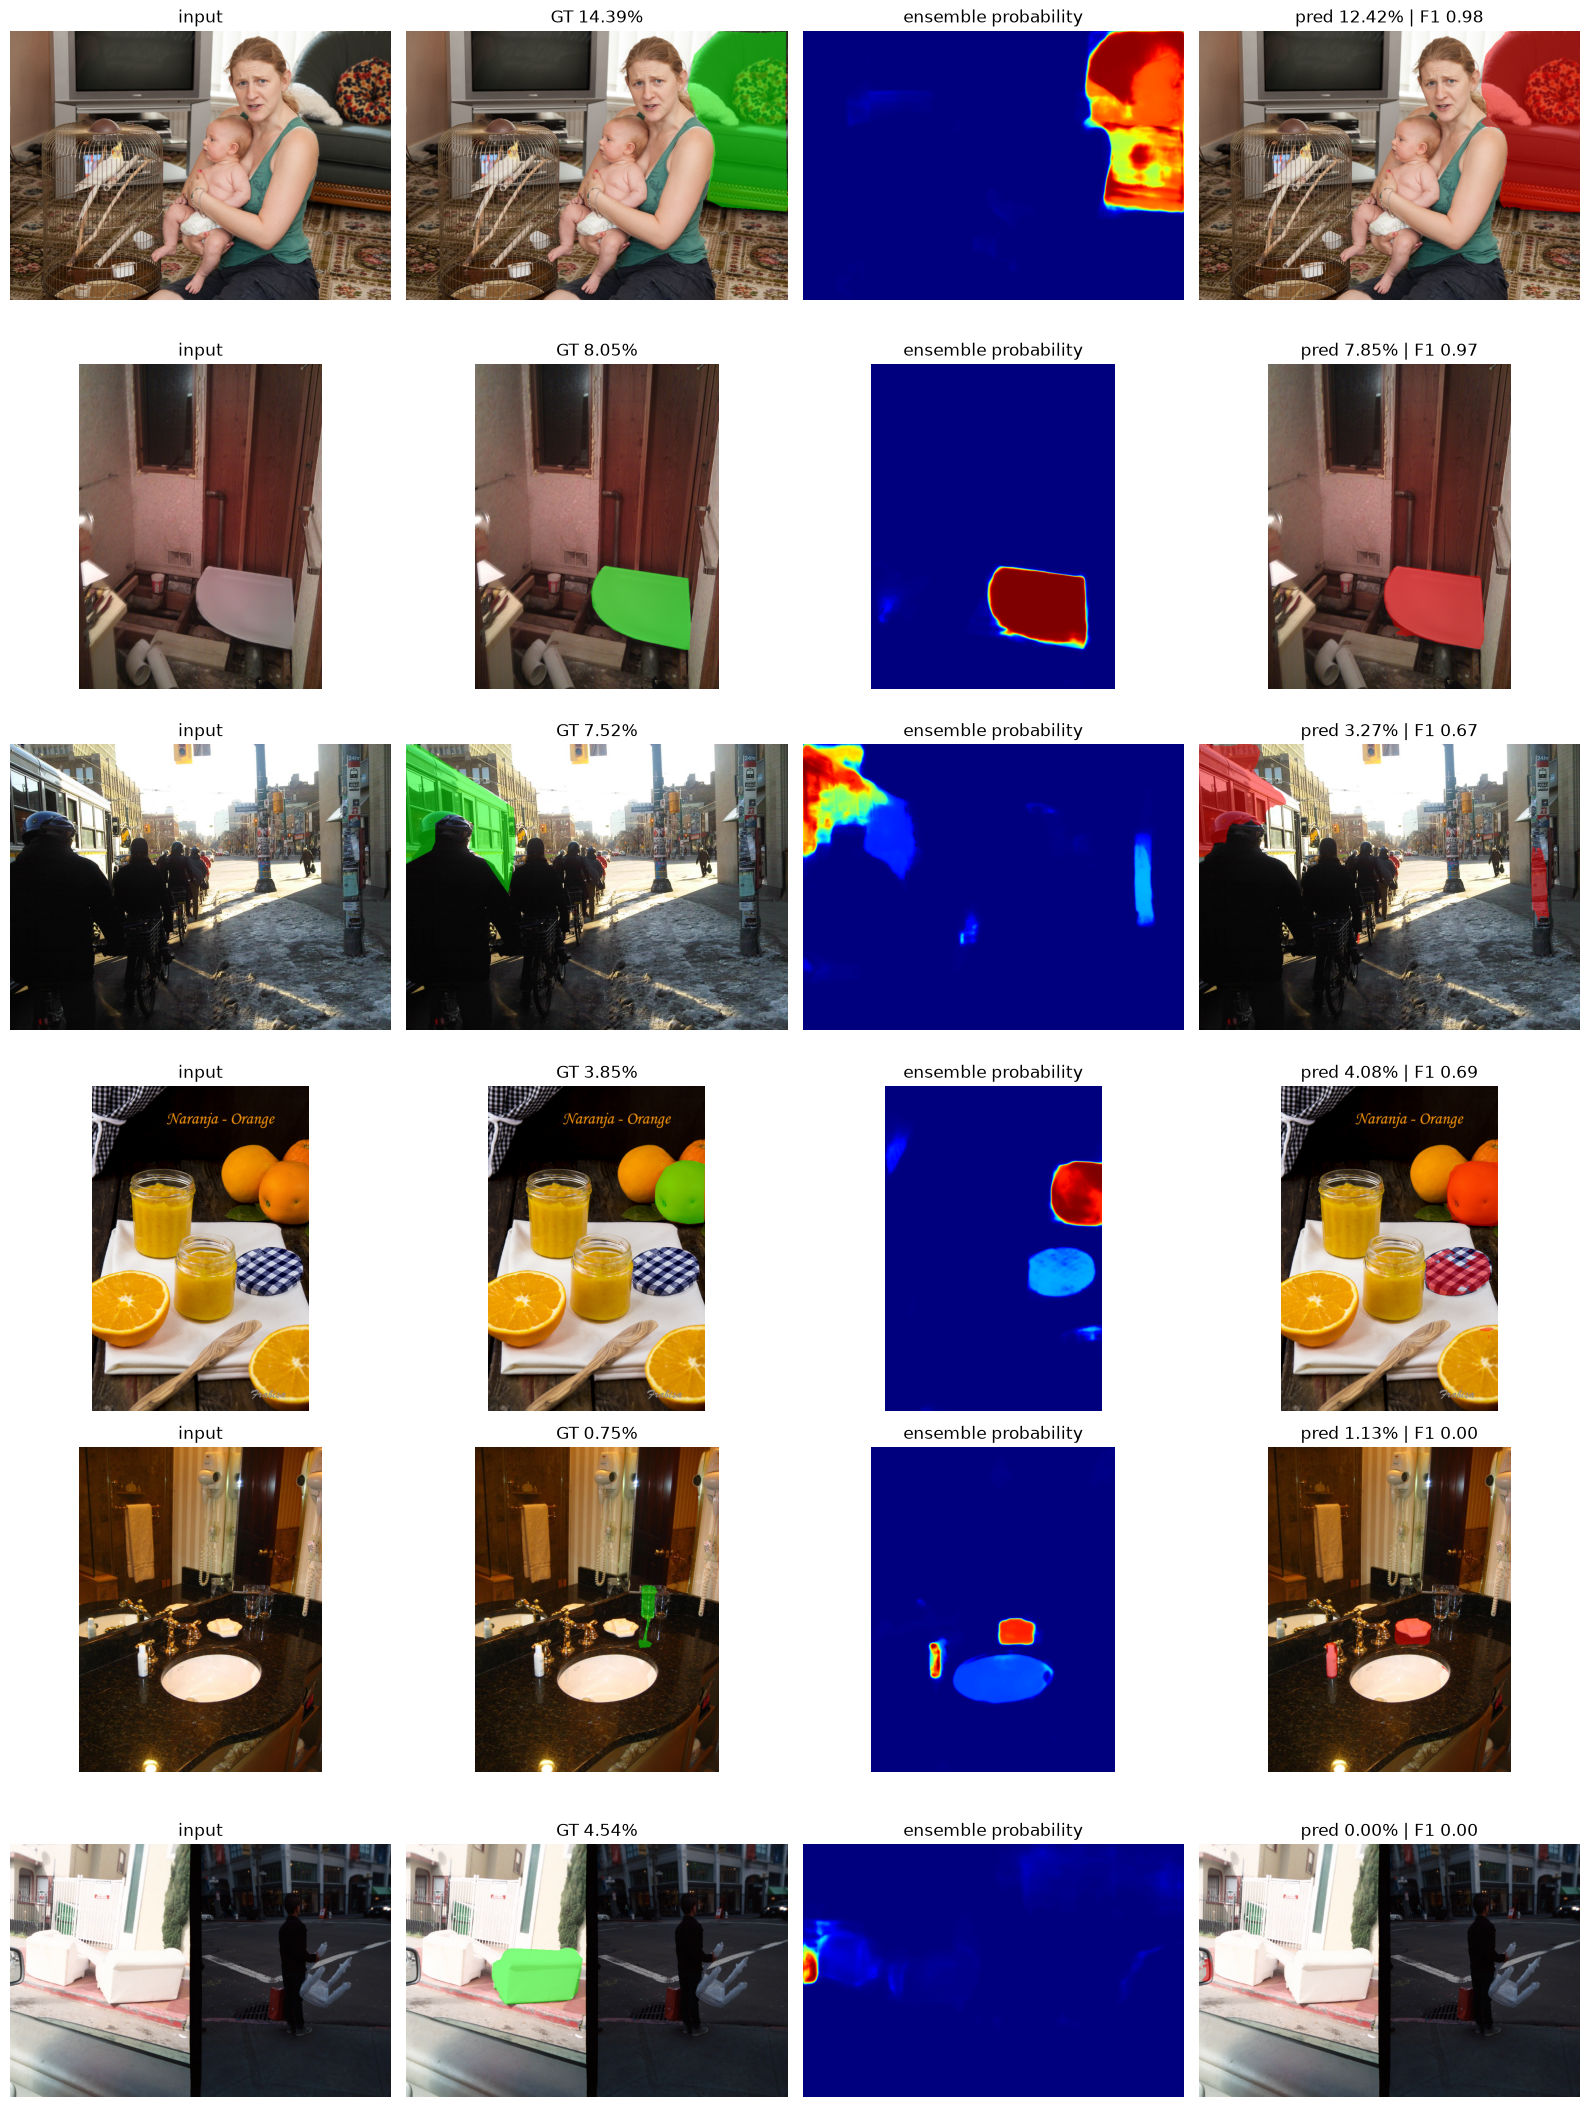

Saved to C:\AI_Image_Project\results\localization\ensemble


In [7]:
# ============================================================
# 7. Visual check + save
# ============================================================
w_best = torch.tensor(COMBOS[BEST_C], device=device, dtype=torch.float32)
f1_test = per_image_f1(S_test, BEST_C)[:, best_t[BEST_C]]
order = np.argsort(f1_test); picks = list(order[-2:][::-1]) + list(order[len(order)//2:len(order)//2 + 2]) + list(order[:2])
fig, axes = plt.subplots(len(picks), 4, figsize=(16, 3.6 * len(picks)))
for r_, k in enumerate(picks):
    img, gt = load_pair(test_idx[k])
    p = torch.tensordot(w_best, torch.stack([predict_prob(m, img) for m in models]), 1).float().cpu().numpy()
    pr = p >= THRS[best_t[BEST_C]]
    og = img.copy(); og[gt] = (0.5 * og[gt] + [0, 127, 0]).astype(np.uint8)
    op = img.copy(); op[pr] = (0.5 * op[pr] + [127, 0, 0]).astype(np.uint8)
    for a_, im_, t_ in zip(axes[r_], [img, og, p, op], ["input", f"GT {At['gt'][k]:.2f}%", "ensemble probability",
                                                         f"pred {EST[BEST_EST][1][k]:.2f}% | F1 {f1_test[k]:.2f}"]):
        a_.imshow(im_, cmap="jet" if t_ == "ensemble probability" else None); a_.set_title(t_); a_.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "ensemble_test_examples.png", dpi=100); plt.show()

loc_table.to_csv(OUT_DIR / "localization_ensemble_metrics.csv", index=False)
quant_table.to_csv(OUT_DIR / "quantification_ensemble_metrics.csv", index=False)
json.dump({"runs": names, "weights": dict(zip(names, COMBOS[BEST_C].round(2).tolist())),
           "threshold": float(THRS[best_t[BEST_C]]), "area_estimator": BEST_EST, "clean_labels": CLEAN_LABELS,
           "test_localization": {k: float(v) for k, v in lt.loc[label(BEST_C)].drop("chosen_on_val").items()},
           "test_quantification": {k: float(v) for k, v in quant_table[(quant_table.Estimator == BEST_EST) &
                                   (quant_table.Split == "Test")].iloc[0].drop(["Estimator", "Split"]).items()}},
          open(OUT_DIR / "ensemble_summary.json", "w"), indent=2)
print("Saved to", OUT_DIR)